# Step 1 — Data: loaders and frozen samples

**Goal:** turn RAGTruth, FaithBench and JudgeBench into one schema
(`id, task, source, subset, context, question, answer, answer_b, human_label, meta`) and freeze seeded samples.

| File | Rows | Purpose |
|---|---|---|
| `ragtruth_test_600.jsonl` | 600 = 3 task types × 2 labels × 100 | Task A main eval |
| `faithbench_250.jsonl` | 125 / 125 | Task A hard mode |
| `judgebench_eval_600.jsonl` | 600 | Task B eval |
| `judgebench_dev_20.jsonl` | 20 | Task B prompt debugging only |
| `ragtruth_pilot_50.jsonl` | 25 / 25 (train split) | Pilot (Step 6) |
| `ragtruth_fewshot_pool.jsonl` | 30 (train split) | M3 anchors are hand-picked from here |

Runtime: **CPU is enough** for this notebook.

In [6]:
# --- 1. Setup: mount Drive, go to the project, install, import ---------------------------
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/LLM_as_Judge_Benchmark'   # <- change if you put it elsewhere
REPO_URL = 'https://github.com/moghbaie/LLM_as_Judge_Benchmark.git'   # optional: 'https://github.com/<you>/LLM_as_Judge_Benchmark.git' to clone instead

import os, sys, subprocess
if REPO_URL and not os.path.exists(PROJECT_DIR):
    subprocess.run(['git', 'clone', REPO_URL, PROJECT_DIR], check=True)
os.chdir(PROJECT_DIR)
!pip -q install -r requirements.txt
sys.path.insert(0, os.path.join(PROJECT_DIR, 'src'))

import pandas as pd
pd.set_option('display.max_colwidth', 100); pd.set_option('display.width', 200)
print('cwd:', os.getcwd()); print(os.listdir('.'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cwd: /content/drive/MyDrive/LLM_as_Judge_Benchmark
['.git', '.gitattributes', '.gitignore', 'LLM-as-Judge Benchmark Open-Weight vs Frontier — Project Plan.md', 'PLAN.md', 'data', 'notebooks', 'pyproject.toml', 'requirements.txt', 'src', 'tests']


## 2. Unit tests first (offline, ~1 s)
These test the *logic* on tiny hand-made fixtures: label mapping, quality filter, length filter,
balanced sampling (exact cell counts, determinism, input-order invariance), JSONL round-trip.
The 5 `frozen` tests are skipped until `data/manifest.json` exists.

In [7]:
!python -m pytest -q -rs tests/test_step1_data.py

.................                                                        [100%]
17 passed in 2.22s


## 3. Download raw data (pinned revisions) and look at it

In [8]:
from ljbench import config, build_data as bd
print('RAGTruth  ', config.RAGTRUTH_REPO, config.RAGTRUTH_REVISION[:10])
print('JudgeBench', config.JUDGEBENCH_REPO, config.JUDGEBENCH_REVISION[:10])
print('FaithBench', config.FAITHBENCH_URL)

raw = bd.fetch_all_raw()
for name, df in raw.items():
    print(f'\n=== RAW {name}: {df.shape}')
    display(bd.preview(df, 2, 80))

RAGTruth   wandb/RAGTruth-processed eb4f4b9d1b
JudgeBench ScalerLab/JudgeBench 57dd5e0b98
FaithBench https://raw.githubusercontent.com/vectara/FaithBench/023b72b2996f448eed9d25c882ad130679796ec2/FaithBench.csv


README.md:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 22.3MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.88MB            

... (13 outputs left out)


=== RAW faithbench: (800, 5)


,source,summary,LLM,worst-label,best-label
0,"Poseidon (film) . Poseidon grossed $ 181,674,817 at the worldwide box office ...","The film ""Poseidon"" grossed $181,674,817 at the worldwide box office, with a...",mistralai/Mistral-7B-Instruct-v0.3,Unwanted,Unwanted
1,"Poseidon (film) . Poseidon grossed $ 181,674,817 at the worldwide box office ...","Poseidon, a film, grossed $181,674,817 worldwide from a budget of $160 million.",microsoft/Phi-3-mini-4k-instruct,Consistent,Consistent



=== RAW judgebench: (620, 9)


,pair_id,original_id,source,question,response_model,response_A,response_B,label,split
0,e302b0a0-28d5-5a3c-b1af-fedcf5543e72,1420.0,mmlu-pro-law,"A college student initiated a criminal case against his former roommate, clai...",gpt-4o-2024-05-13,To determine if evidence of the student's reputation for dishonesty is admiss...,To determine whether the former roommate can use evidence of the college stud...,A>B,gpt
1,2d989dfb-7cf0-549e-945c-3dd060d1fad5,1748.0,mmlu-pro-law,A ceramics studio contracted with an artist to produce cups and saucers desig...,gpt-4o-2024-05-13,Let's carefully analyze the given problem and the potential answers step by s...,To determine whether the studio's evidence of industry practice is admissible...,A>B,gpt


**What to look for:** RAGTruth marks hallucinations as a JSON list of spans in `hallucination_labels`
(`'[]'` = clean). FaithBench gives per-summary `worst-label` / `best-label`. JudgeBench has `response_A`,
`response_B` and `label` = `A>B` / `B>A`.

## 4. Convert to the unified schema

In [9]:
items = bd.convert_all(raw)          # also runs schema.validate() on each
for name, df in items.items():
    print(f'\n=== CONVERTED {name}: {len(df)} rows')
    display(bd.preview(df, 2, 70, ['id', 'subset', 'question', 'answer', 'human_label', 'meta']))
    display(bd.label_table(df))


=== CONVERTED ragtruth_test: 2675 rows


,id,subset,question,answer,human_label,meta
0,ragtruth-24,Summary,Summarize the following news within 86 words:,"The FBI has charged a Philadelphia woman, Keonna Thomas, with tryin...",SUPPORTED,"{""split"": ""test"", ""generator"": ""gpt-4-0613"", ""quality"": ""good"", ""n_..."
1,ragtruth-25,Summary,Summarize the following news within 86 words:,"A Philadelphia woman, Keonna Thomas, has been charged by the FBI fo...",SUPPORTED,"{""split"": ""test"", ""generator"": ""gpt-3.5-turbo-0613"", ""quality"": ""go..."


human_label,SUPPORTED,UNSUPPORTED,TOTAL
subset,,,
Data2txt,321,579,900
QA,715,160,875
Summary,696,204,900
TOTAL,1732,943,2675



=== CONVERTED ragtruth_train: 14942 rows


,id,subset,question,answer,human_label,meta
0,ragtruth-0,Summary,Summarize the following news within 116 words:,The Anne Frank House has revealed that Anne Frank and her older sis...,SUPPORTED,"{""split"": ""train"", ""generator"": ""gpt-4-0613"", ""quality"": ""good"", ""n..."
1,ragtruth-1,Summary,Summarize the following news within 116 words:,New research released by the Anne Frank House reveals that Anne Fra...,SUPPORTED,"{""split"": ""train"", ""generator"": ""gpt-3.5-turbo-0613"", ""quality"": ""g..."


human_label,SUPPORTED,UNSUPPORTED,TOTAL
subset,,,
Data2txt,1623,3672,5295
QA,3346,1546,4892
Summary,3275,1480,4755
TOTAL,8244,6698,14942


... (2 outputs left out)

human_label,SUPPORTED,UNSUPPORTED,TOTAL
subset,,,
Anthropic/claude-3-5-sonnet-20240620,24,46,70
Qwen/Qwen2.5-7B-Instruct,18,58,76
cohere/command-r-08-2024,14,57,71
google/gemini-1.5-flash-001,29,45,74
meta-llama/Meta-Llama-3.1-70B-Instruct,28,47,75
meta-llama/Meta-Llama-3.1-8B-Instruct,24,44,68
microsoft/Phi-3-mini-4k-instruct,16,57,73
mistralai/Mistral-7B-Instruct-v0.3,18,56,74
openai/GPT-3.5-Turbo,34,38,72



=== CONVERTED judgebench: 620 rows


,id,subset,question,answer,human_label,meta
0,judgebench-e302b0a0-28d5-5a3c-b1af-fedcf5543e72,mmlu-pro,A college student initiated a criminal case against his former room...,To determine if evidence of the student's reputation for dishonesty...,A,"{""fine_source"": ""mmlu-pro-law"", ""response_model"": ""gpt-4o-2024-05-1..."
1,judgebench-2d989dfb-7cf0-549e-945c-3dd060d1fad5,mmlu-pro,A ceramics studio contracted with an artist to produce cups and sau...,Let's carefully analyze the given problem and the potential answers...,A,"{""fine_source"": ""mmlu-pro-law"", ""response_model"": ""gpt-4o-2024-05-1..."


human_label,A,B,TOTAL
subset,,,
livebench-math,55,35,90
livebench-reasoning,81,68,149
livecodebench,35,38,73
mmlu-pro,165,143,308
TOTAL,336,284,620


**Explanation**
- RAGTruth test: 2,700 → **2,675** after dropping 25 `incorrect_refusal`/`truncated` rows.
  QA has only **160** hallucinated answers (the bottleneck for 100 per cell).
- FaithBench: 800 → **723** after dropping 77 `Questionable`. Only **238 SUPPORTED** (Consistent+Benign), so 125/125 is feasible.
- JudgeBench: 620 pairs, A wins 336 vs B 284 (slightly unbalanced; our A/B swap in Step 2 removes this bias).

## 5. Length profile (estimated tokens = chars / 3.5)

,n,p50,p90,p99,max,> 6000
ragtruth_test,2675,852,1591,2577,3373,0
ragtruth_train,14942,850,1501,2677,3579,0
faithbench,723,440,1518,1666,1785,0
judgebench,620,1128,1982,2410,2566,0


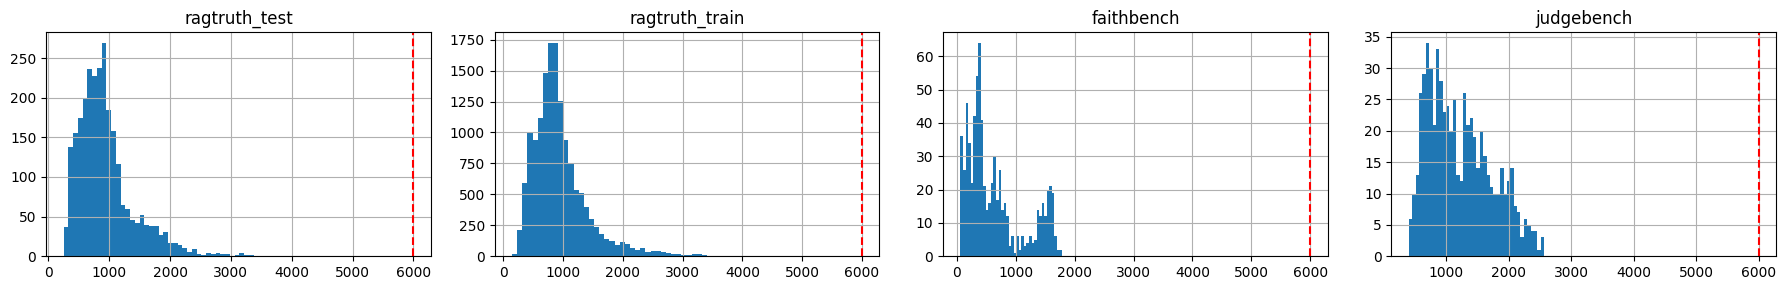

In [10]:
import matplotlib.pyplot as plt
from ljbench.sampling import input_tokens
display(bd.length_profile(items))
fig, axes = plt.subplots(1, 4, figsize=(18, 3))
for ax, (name, df) in zip(axes, items.items()):
    input_tokens(df).hist(ax=ax, bins=40); ax.set_title(name); ax.axvline(config.MAX_INPUT_TOKENS, color='r', ls='--')
plt.tight_layout(); plt.show()

Budget: vLLM `max_model_len=8192` = input ≤ 6,000 + prompt template + ≤ 1,024 output tokens.
The longest item is ~3,600 estimated tokens, so **nothing is dropped**. Small models are not disadvantaged by truncation.

## 6. Sample and freeze

In [11]:
from pathlib import Path
from ljbench.io_utils import sha256
samples, dropped = bd.build_samples(items)

# If frozen files already exist, DO NOT overwrite: rebuild elsewhere and prove they are identical.
target = Path('data') if not Path('data/manifest.json').exists() else Path('/content/rebuild')
manifest = bd.save(samples, target, dropped)
print('written to', target, '| dropped:', dropped)
if target != Path('data'):
    for f in manifest['files']:
        same = sha256(target / f) == sha256(Path('data') / f)
        print(('identical  ' if same else 'DIFFERENT! ') + f)
pd.DataFrame(manifest['files']).T[['rows', 'labels']]

written to /content/rebuild | dropped: {'ragtruth_test': 0, 'ragtruth_train': 0, 'faithbench': 0, 'judgebench': 0, 'ragtruth_train_context_overlap': 0}
identical  ragtruth_test_600.jsonl
identical  faithbench_250.jsonl
identical  ragtruth_pilot_50.jsonl
identical  ragtruth_fewshot_pool.jsonl
identical  judgebench_dev_20.jsonl
identical  judgebench_eval_600.jsonl


,rows,labels
ragtruth_test_600.jsonl,600,"{'SUPPORTED': 300, 'UNSUPPORTED': 300}"
faithbench_250.jsonl,250,"{'SUPPORTED': 125, 'UNSUPPORTED': 125}"
ragtruth_pilot_50.jsonl,50,"{'SUPPORTED': 25, 'UNSUPPORTED': 25}"
ragtruth_fewshot_pool.jsonl,30,"{'SUPPORTED': 15, 'UNSUPPORTED': 15}"
judgebench_dev_20.jsonl,20,"{'A': 13, 'B': 7}"
judgebench_eval_600.jsonl,600,"{'A': 323, 'B': 277}"


## 7. Look at one frozen item from each file

In [12]:
from ljbench.io_utils import read_jsonl
for f in sorted(Path('data').glob('*.jsonl')):
    df = read_jsonl(f)
    print(f'\n######## {f.name}  ({len(df)} rows)')
    display(bd.preview(df, 1, 160).T)
fb = read_jsonl('data/faithbench_250.jsonl'); jb = read_jsonl('data/judgebench_eval_600.jsonl')
display(pd.crosstab(fb.subset, fb.human_label)); display(pd.crosstab(jb.subset, jb.human_label))


######## faithbench_250.jsonl  (250 rows)


,0
id,faithbench-0271
task,faithfulness
source,faithbench
subset,microsoft/Phi-3-mini-4k-instruct
context,"James Jones (author) . He won the 1952 National Book Award for his first published novel , From ..."
question,Summarize the following passage.
answer,"James Jones is an author who won the 1952 National Book Award for his first published novel, ""Fr..."
answer_b,None
human_label,UNSUPPORTED
meta,"{""best_label"": ""Unwanted"", ""generator"": ""microsoft/Phi-3-mini-4k-instruct"", ""worst_label"": ""Unwa..."



######## judgebench_dev_20.jsonl  (20 rows)


,0
id,judgebench-c0fceb61-37b0-5049-84c3-9add01413cc8
task,pairwise
source,judgebench
subset,mmlu-pro
context,
question,"A solid, metal object is isolated from other charges and has charge distributed on its surface. ..."
answer,"Sure, let's break it down step by step to analyze each statement and determine which one is corr..."
answer_b,Certainly! Let's break down the problem step by step by analyzing each option provided: (A) **T...
human_label,A
meta,"{""fine_source"": ""mmlu-pro-physics"", ""original_id"": ""10038.0"", ""response_model"": ""gpt-4o-2024-05-..."



######## judgebench_eval_600.jsonl  (600 rows)


,0
id,judgebench-1ffd3127-ed25-5ab3-b793-ba82e8bbfbe0
task,pairwise
source,judgebench
subset,livecodebench
context,
question,You are given an array of positive integers nums. You have to check if it is possible to select ...
answer,"class Solution: def hasTrailingZeros(self, nums: List[int]) -> bool: def has_trailin..."
answer_b,"class Solution: def hasTrailingZeros(self, nums: List[int]) -> bool: # Check if ther..."
human_label,A
meta,"{""fine_source"": ""livecodebench"", ""original_id"": null, ""response_model"": ""gpt-4o-2024-05-13"", ""sp..."


... (4 outputs left out)


######## ragtruth_test_600.jsonl  (600 rows)


,0
id,ragtruth-8077
task,faithfulness
source,ragtruth
subset,Data2txt
context,"{'name': 'Bogo SB', 'address': '1114 State St', 'city': 'Santa Barbara', 'state': 'CA', 'catego..."
question,Instruction: Write an objective overview about the following local business based only on the pr...
answer,"Bogo SB is a local business located at 1114 State St in Santa Barbara, CA. The business offers a..."
answer_b,None
human_label,SUPPORTED
meta,"{""generator"": ""gpt-3.5-turbo-0613"", ""n_spans"": 0, ""quality"": ""good"", ""span_types"": [], ""split"": ..."


human_label,SUPPORTED,UNSUPPORTED
subset,,
Anthropic/claude-3-5-sonnet-20240620,13,11
Qwen/Qwen2.5-7B-Instruct,13,17
cohere/command-r-08-2024,8,13
google/gemini-1.5-flash-001,13,17
meta-llama/Meta-Llama-3.1-70B-Instruct,13,13
meta-llama/Meta-Llama-3.1-8B-Instruct,15,10
microsoft/Phi-3-mini-4k-instruct,8,11
mistralai/Mistral-7B-Instruct-v0.3,10,18
openai/GPT-3.5-Turbo,19,7


human_label,A,B
subset,,
livebench-math,55,32
livebench-reasoning,77,66
livecodebench,34,38
mmlu-pro,157,141


## 8. Integration tests on the frozen files (gate)

In [13]:
!python -m pytest -q -rs tests/test_step1_data.py

.................                                                        [100%]
17 passed in 1.11s


## Result and explanation

Expected: **17 passed, 0 skipped.**

| Check | What it proves |
|---|---|
| `test_hashes_match_manifest` | The frozen files have not been edited since they were built |
| `test_frozen_schema_and_sizes` | Every file has the right size and passes the schema validator |
| `test_frozen_balance` | RAGTruth has exactly 100 per (task type × label) cell; FaithBench is exactly 125/125 |
| `test_no_leakage_between_splits` | Pilot and few-shot items come from train, share no source document with test, and JudgeBench dev ∩ eval = ∅ |
| `test_all_within_length_budget` | No item can be truncated by an 8k context |

Notes for the blog / analysis:
- **Balanced sample ≠ real-world prevalence.** The balanced accuracy is fine as is, but precision must be reweighted to 10–20% (Step 3).
- **FaithBench generators are not balanced** (e.g. GPT-3.5 has 19 SUPPORTED / 7 UNSUPPORTED). Report FaithBench overall, not per generator.
- **JudgeBench eval is 323 A / 277 B.** Running both orders (Step 2) makes the effective gold set 50/50.
- The rebuild in cell 6 reproduces every file byte-for-byte, so the samples are fully determined by `config.py`.

**Gate passed → Step 2 (prompts + parsing).**